<a href="https://colab.research.google.com/github/kauazin05/CIAO_KKG_2026/blob/main/lab1_aula_10_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!mkdir -p AULA_10

In [12]:
%%writefile AULA_10/lab01_aula10.py
"""
AULA 10 - Motor de Inferencia Mamdani e Superficie 3D (Sprint 2 da AC-3)
Disciplina: Inteligencia Computacional
"""

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzzy
from skfuzzy import control as ctrl


# ============================================================
# 1. FUZZIFICACAO - Variaveis e Funcoes de Pertinencia
# ============================================================
def criar_sistema_fuzzy():
    impacto = ctrl.Antecedent(np.arange(0, 101, 1), 'impacto')
    explorabilidade = ctrl.Antecedent(np.arange(0, 11, 1), 'explorabilidade')
    urgencia = ctrl.Consequent(np.arange(0, 101, 1), 'urgencia')

    urgencia.defuzzify_method = 'centroid'

    impacto['baixo'] = fuzzy.trimf(impacto.universe, [0, 0, 40])
    impacto['medio'] = fuzzy.trimf(impacto.universe, [20, 50, 80])
    impacto['alto'] = fuzzy.trapmf(impacto.universe, [60, 80, 100, 100])

    explorabilidade['baixa'] = fuzzy.trimf(explorabilidade.universe, [0, 0, 4])
    explorabilidade['moderada'] = fuzzy.trimf(explorabilidade.universe, [2, 5, 8])
    explorabilidade['alta'] = fuzzy.trimf(explorabilidade.universe, [6, 10, 10])

    urgencia['baixa'] = fuzzy.trimf(urgencia.universe, [0, 0, 30])
    urgencia['media'] = fuzzy.trimf(urgencia.universe, [20, 50, 70])
    urgencia['alta'] = fuzzy.trimf(urgencia.universe, [60, 80, 90])
    urgencia['critica'] = fuzzy.trapmf(urgencia.universe, [80, 90, 100, 100])

    return impacto, explorabilidade, urgencia


# ============================================================
# 2. INFERENCIA - Matriz de Regras 3x3 (9 regras)
# ============================================================
def construir_motor_inferencia():
    impacto, explorabilidade, urgencia = criar_sistema_fuzzy()

    regras = [
        ctrl.Rule(impacto['baixo'] & explorabilidade['baixa'], urgencia['baixa']),
        ctrl.Rule(impacto['baixo'] & explorabilidade['moderada'], urgencia['baixa']),
        ctrl.Rule(impacto['baixo'] & explorabilidade['alta'], urgencia['media']),
        ctrl.Rule(impacto['medio'] & explorabilidade['baixa'], urgencia['media']),
        ctrl.Rule(impacto['medio'] & explorabilidade['moderada'], urgencia['alta']),
        ctrl.Rule(impacto['medio'] & explorabilidade['alta'], urgencia['alta']),
        ctrl.Rule(impacto['alto'] & explorabilidade['baixa'], urgencia['critica']),
        ctrl.Rule(impacto['alto'] & explorabilidade['moderada'], urgencia['critica']),
        ctrl.Rule(impacto['alto'] & explorabilidade['alta'], urgencia['critica']),
    ]
    sistema_controle = ctrl.ControlSystem(regras)
    return ctrl.ControlSystemSimulation(sistema_controle)


# ============================================================
# 3. DEFUZZIFICACAO - Casos de teste no console
# ============================================================
def simular_casos_teste(simulador):
    casos = [
        ("Minimo Absoluto", 0.0, 0.0),
        ("Baixo Impacto + Alta Explorabilidade (Transicao)", 10.0, 9.0),
        ("Medio Impacto + Moderado", 50.0, 5.0),
        ("Maximo Absoluto", 100.0, 10.0),
    ]
    print("\n=== SIMULACOES DE TESTE DE INFERENCIA ===")
    for nome, imp, exp in casos:
        simulador.input['impacto'] = imp
        simulador.input['explorabilidade'] = exp
        simulador.compute()
        res = simulador.output['urgencia']
        print(f"[{nome}] -> Imp: {imp}% | Exp: {exp} => Urgencia: {res:.2f}%")


# ============================================================
# 4. SUPERFICIE DE DECISAO 3D
# ============================================================
def gerar_superficie_3d(simulador, caminho_saida='AULA_10/results/superficie_decisao.png'):
    Path(caminho_saida).parent.mkdir(parents=True, exist_ok=True)

    x, y = np.meshgrid(np.linspace(0, 100, 20), np.linspace(0, 10, 20))
    z = np.zeros_like(x)

    for i in range(20):
        for j in range(20):
            simulador.input['impacto'] = x[i, j]
            simulador.input['explorabilidade'] = y[i, j]
            simulador.compute()
            z[i, j] = simulador.output['urgencia']

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    surf = ax.plot_surface(x, y, z, cmap='viridis', edgecolor='none', alpha=0.9)
    ax.set_xlabel('Impacto no Negocio (%)')
    ax.set_ylabel('Explorabilidade (0-10)')
    ax.set_zlabel('Urgencia Calculada (%)')
    plt.title('Superficie de Decisao Fuzzy - SOC Autonomo')
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5)
    plt.tight_layout()
    plt.savefig(caminho_saida)
    plt.close()
    print(f"Sucesso: Imagem '{caminho_saida}' gerada com exito!")


# ============================================================
# EXECUCAO PRINCIPAL
# ============================================================
if __name__ == "__main__":
    sim = construir_motor_inferencia()
    simular_casos_teste(sim)
    gerar_superficie_3d(sim)

Writing AULA_10/lab01_aula10.py


In [13]:
!python AULA_10/lab01_aula10.py


=== SIMULACOES DE TESTE DE INFERENCIA ===
[Minimo Absoluto] -> Imp: 0.0% | Exp: 0.0 => Urgencia: 10.00%
[Baixo Impacto + Alta Explorabilidade (Transicao)] -> Imp: 10.0% | Exp: 9.0 => Urgencia: 46.50%
[Medio Impacto + Moderado] -> Imp: 50.0% | Exp: 5.0 => Urgencia: 76.67%
[Maximo Absoluto] -> Imp: 100.0% | Exp: 10.0 => Urgencia: 92.22%
Sucesso: Imagem 'AULA_10/results/superficie_decisao.png' gerada com exito!


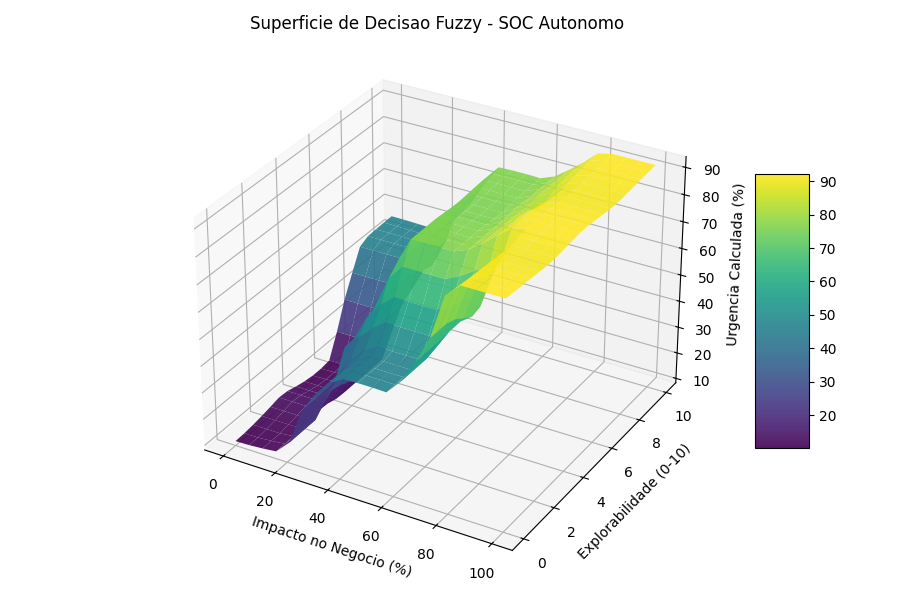

In [14]:
from IPython.display import Image
Image('AULA_10/results/superficie_decisao.png')